In [2]:

# 项目三：策略效果评估——A/B测试框架搭建
# 数据集：Cookie Cats A/B Testing
# 作者：李霄雪

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# 设置中文字体，避免图表乱码
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 设置随机种子，保证 Bootstrap 结果可复现
np.random.seed(42)

# ---------- 1. 读取数据 ----------
data_path = r'D:\projects\taobao-user-behavior-analysis\data\cookie_cats.csv'
chart_dir = r'D:\projects\taobao-user-behavior-analysis\charts'
os.makedirs(chart_dir, exist_ok=True)

df = pd.read_csv(data_path)

print("=" * 50)
print("数据形状:", df.shape)
print("\n前5行:")
print(df.head())
print("\n实验分组分布:")
print(df['version'].value_counts())
print("\n缺失值:")
print(df.isnull().sum())
print("=" * 50)

数据形状: (90189, 5)

前5行:
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True

实验分组分布:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

缺失值:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


In [3]:
# ---------- 2. 分组与留存率计算 ----------
control = df[df['version'] == 'gate_30']
treatment = df[df['version'] == 'gate_40']

results = {}

for metric in ['retention_1', 'retention_7']:
    c_count = control[metric].sum()
    t_count = treatment[metric].sum()
    c_n = len(control)
    t_n = len(treatment)
    
    c_p = c_count / c_n
    t_p = t_count / t_n
    diff = t_p - c_p
    
    # 双样本比例 Z 检验
    z_stat, p_value = proportions_ztest(
        [t_count, c_count],
        [t_n, c_n],
        alternative='two-sided'
    )
    
    # 比例差 95% 置信区间（Wald 近似）
    se = np.sqrt(t_p * (1 - t_p) / t_n + c_p * (1 - c_p) / c_n)
    ci_low = diff - 1.96 * se
    ci_high = diff + 1.96 * se
    
    results[metric] = {
        'control_rate': c_p,
        'treatment_rate': t_p,
        'diff': diff,
        'z': z_stat,
        'p': p_value,
        'ci': (ci_low, ci_high)
    }
    
    print(f"\n===== {metric} =====")
    print(f"对照组 gate_30 留存率: {c_p:.4%}")
    print(f"实验组 gate_40 留存率: {t_p:.4%}")
    print(f"绝对差异 (Lift): {diff:.4%}")
    print(f"95% 置信区间: [{ci_low:.4%}, {ci_high:.4%}]")
    print(f"Z 统计量: {z_stat:.4f}")
    print(f"P 值: {p_value:.4f}")
    
    if p_value < 0.05:
        print("结论：P < 0.05，两组差异具有统计学显著性。")
    else:
        print("结论：P >= 0.05，无法拒绝原假设，两组无显著差异。")


===== retention_1 =====
对照组 gate_30 留存率: 44.8188%
实验组 gate_40 留存率: 44.2283%
绝对差异 (Lift): -0.5905%
95% 置信区间: [-1.2393%, 0.0582%]
Z 统计量: -1.7841
P 值: 0.0744
结论：P >= 0.05，无法拒绝原假设，两组无显著差异。

===== retention_7 =====
对照组 gate_30 留存率: 19.0201%
实验组 gate_40 留存率: 18.2000%
绝对差异 (Lift): -0.8201%
95% 置信区间: [-1.3282%, -0.3121%]
Z 统计量: -3.1644
P 值: 0.0016
结论：P < 0.05，两组差异具有统计学显著性。


In [4]:
# ---------- 3. Bootstrap 重抽样 ----------
def bootstrap_diff(data, metric, n_iter=10000):
    """
    对给定指标进行 Bootstrap 重抽样，返回两组留存率差值（gate_30 - gate_40）的数组。
    差值 > 0 表示 gate_30 留存率更高。
    """
    diffs = []
    for _ in range(n_iter):
        sample = data.sample(frac=1, replace=True)
        c_rate = sample[sample['version'] == 'gate_30'][metric].mean()
        t_rate = sample[sample['version'] == 'gate_40'][metric].mean()
        diffs.append(c_rate - t_rate)
    return np.array(diffs)

n_iter = 10000  # 迭代次数，可改为 5000 加快速度，但 10000 更稳定
boot_results = {}

for metric in ['retention_1', 'retention_7']:
    diffs = bootstrap_diff(df, metric, n_iter=n_iter)
    prob = (diffs > 0).mean()  # gate_30 优于 gate_40 的概率
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    
    boot_results[metric] = {
        'diffs': diffs,
        'prob': prob,
        'ci': (ci_low, ci_high)
    }
    
    print(f"\n===== Bootstrap: {metric} =====")
    print(f"重抽样次数: {n_iter}")
    print(f"gate_30 留存率高于 gate_40 的概率: {prob:.4%}")
    print(f"差异的 95% 置信区间: [{ci_low:.4%}, {ci_high:.4%}]")
    if ci_low > 0:
        print("结论：置信区间完全在 0 以上，gate_30 显著更优。")
    elif ci_high < 0:
        print("结论：置信区间完全在 0 以下，gate_40 显著更优。")
    else:
        print("结论：置信区间包含 0，差异不显著。")


===== Bootstrap: retention_1 =====
重抽样次数: 10000
gate_30 留存率高于 gate_40 的概率: 96.6000%
差异的 95% 置信区间: [-0.0469%, 1.2147%]
结论：置信区间包含 0，差异不显著。

===== Bootstrap: retention_7 =====
重抽样次数: 10000
gate_30 留存率高于 gate_40 的概率: 99.9100%
差异的 95% 置信区间: [0.3198%, 1.3293%]
结论：置信区间完全在 0 以上，gate_30 显著更优。


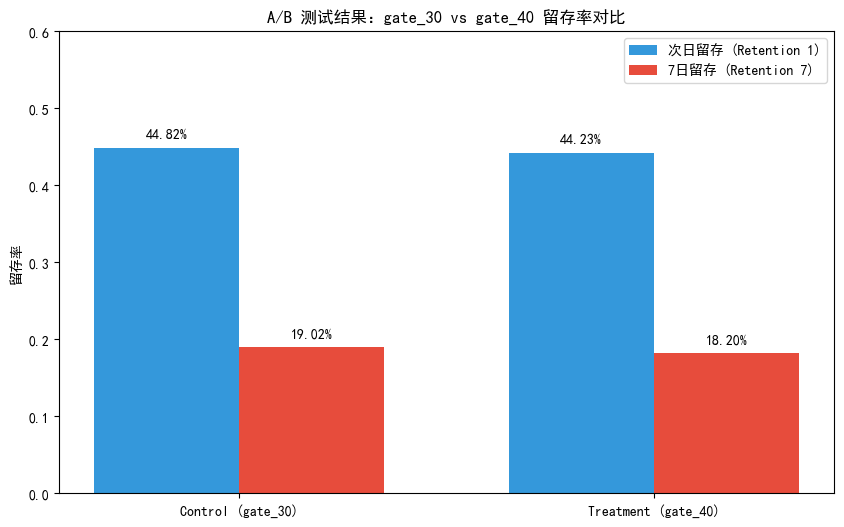

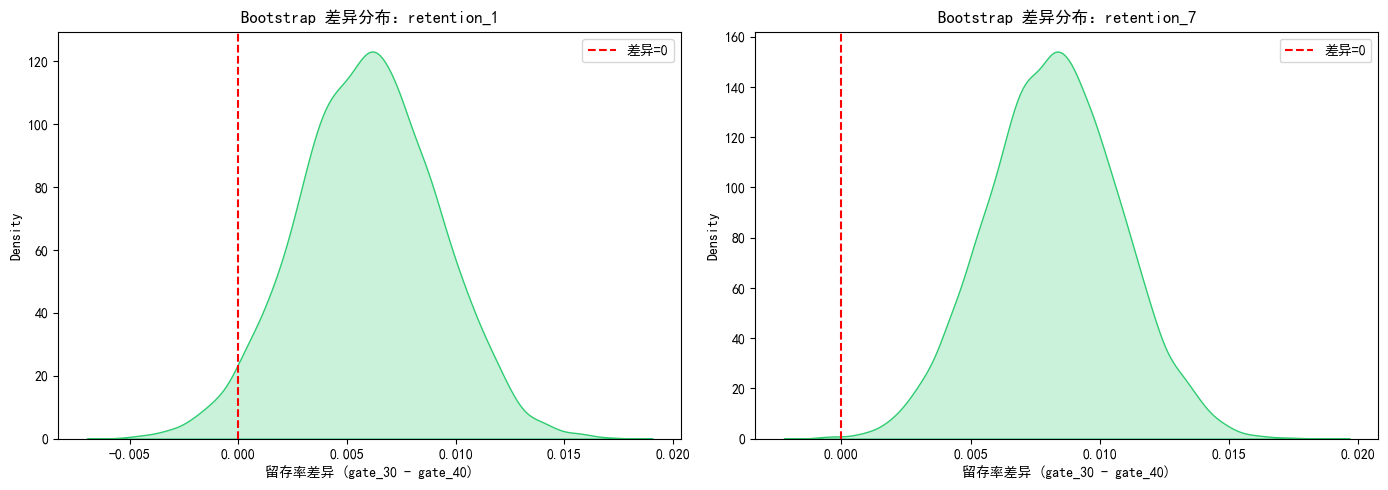

In [5]:
# ---------- 4. 可视化 ----------
# 4.1 留存率对比柱状图
plot_df = pd.DataFrame({
    'Group': ['Control (gate_30)', 'Treatment (gate_40)'],
    'Retention 1': [
        results['retention_1']['control_rate'],
        results['retention_1']['treatment_rate']
    ],
    'Retention 7': [
        results['retention_7']['control_rate'],
        results['retention_7']['treatment_rate']
    ]
})

x = np.arange(len(plot_df['Group']))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, plot_df['Retention 1'], width,
               label='次日留存 (Retention 1)', color='#3498db')
bars2 = ax.bar(x + width/2, plot_df['Retention 7'], width,
               label='7日留存 (Retention 7)', color='#e74c3c')

ax.set_ylabel('留存率')
ax.set_title('A/B 测试结果：gate_30 vs gate_40 留存率对比')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Group'])
ax.legend()
ax.set_ylim(0, 0.6)

# 添加数值标签
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.2%}', ha='center', va='bottom')

plt.savefig(os.path.join(chart_dir, 'ab_test_retention_bar.png'), dpi=150, bbox_inches='tight')
plt.show()

# 4.2 Bootstrap 差异分布 KDE 图
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['retention_1', 'retention_7']):
    diffs = boot_results[metric]['diffs']
    sns.kdeplot(diffs, ax=ax, fill=True, color='#2ecc71')
    ax.axvline(0, color='red', linestyle='--', label='差异=0')
    ax.set_xlabel('留存率差异 (gate_30 - gate_40)')
    ax.set_title(f'Bootstrap 差异分布：{metric}')
    ax.legend()
    
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, 'ab_test_bootstrap_kde.png'), dpi=150, bbox_inches='tight')
plt.show()